SAME as neural network_5_bis but:

- initial weights and biases are taken from standard normal distribution (so max_bias and max_weight are no longer parameters)
- instead of iterations and fraction we now use epochs and batch size
- added an extra version of the neural network, using the delta method for backpropagation

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random

In [69]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [70]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [71]:
def grad(act, wt, bs, ins, outs):
    
    gr_act = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    ind = []   
    for i in range(L):
        ind.append(list(range(len(act[i]))))


    for i in range(L-1): 
        for j in range(len(act[i])):
            gr_act[i][j] = sum([2 * (act[-1][k] - outs[k]) * sigma_der(np.dot(wt[-1][k], act[-2]) + bs[-1][k]) * (wt[-1][k][j] if i == L-2 
                else sum([wt[-1][k][l] * sigma_der(np.dot(wt[-2][l], act[-3]) + bs[-2][l]) * (wt[-2][l][j] if i == L-3 
                else sum([wt[-2][l][m] * sigma_der(np.dot(wt[-3][m], act[-4]) + bs[-3][m]) * (wt[-3][m][j] if i == L-4 
                else sum([wt[-3][m][n] * sigma_der(np.dot(wt[-4][n], act[-5]) + bs[-4][n]) * (wt[-4][n][j] if i == L-5 
                else sum([wt[-4][n][o] * sigma_der(np.dot(wt[-5][o], act[-6]) + bs[-5][o]) * (wt[-5][o][j] if i == L-6
                else sum([wt[-5][o][p] * sigma_der(np.dot(wt[-6][p], act[-7]) + bs[-6][p]) * (wt[-6][p][j] if i == L-7
                else sum([wt[-6][p][q] * sigma_der(np.dot(wt[-7][q], act[-8]) + bs[-7][q]) * (wt[-7][q][j] if i == L-8
                else sum([wt[-7][q][r] * sigma_der(np.dot(wt[-8][r], act[-9]) + bs[-8][r]) * (wt[-8][r][j] if i == L-9
                else sum([wt[-8][r][s] * sigma_der(np.dot(wt[-9][s], act[-10]) + bs[-9][s]) * (wt[-9][s][j] if i == L-10 
                else sum([wt[-9][s][t] * sigma_der(np.dot(wt[-10][t], act[-11]) + bs[-10][t]) * wt[-10][t][j] 
                    for t in ind[-10]])) for s in ind[-9]])) for r in ind[-8]])) for q in ind[-7]])) for p in ind[-6]])) 
                    for o in ind[-5]])) for n in ind[-4]])) for m in ind[-3]])) for l in ind[-2]])) for k in ind[-1]])
            
    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                gr_bs[i][j] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])
        elif i == 0:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j])
        else:
            for j in range(len(bs[i])):
                gr_bs[i][j] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j])

    
    for i in range(L):
        if i == L-1:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = 2*(act[i][j] - outs[j]) * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]
        elif i == 0:
            for j in range(len(bs[i])):
                for k in range(len(ins)):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], ins) + bs[i][j]) * ins[k]
        else:
            for j in range(len(bs[i])):
                for k in range(len(bs[i-1])):
                    gr_wt[i][j][k] = gr_act[i][j] * sigma_der(np.dot(wt[i][j], act[i-1]) + bs[i][j]) * act[i-1][k]         

    
    return gr_act, gr_wt, gr_bs

In [161]:
def grad_2(act, wt, bs, ins, outs):
    
    delta = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    delta[-1] = 2*(act[-1] - outs) * sigma_der(np.dot(wt[-1], act[-2]) + bs[-1])

    for i in range(2,L):
        delta[-i] = np.dot(wt[-i+1].T, delta[-i+1]) * sigma_der(np.dot(wt[-i], act[-i-1]) + bs[-i])

    delta[-L] = np.dot(wt[-L+1].T, delta[-L+1]) * sigma_der(np.dot(wt[-L], ins) + bs[-L])

    gr_bs = delta

    for j in range(len(act[0])):
        for k in range(len(ins)):
            gr_wt[0][j][k] = ins[k] * delta[0][j]
    
    for l in range(1,L):
        for j in range(len(act[l])):
            for k in range(len(act[l-1])):
                gr_wt[l][j][k] = act[l-1][k] * delta[l][j]
                
    
    return gr_wt, gr_bs

In [158]:
def neural_network(inputs, outputs, nodes, learning_rate, epochs, batch_size):

    nodes.append(outputs.shape[1])
    nodes.insert(0, inputs.shape[1])
    
    biases = [np.random.randn(y) for y in nodes[1:]]
    weights = [np.random.randn(x, y) for x, y in zip(nodes[1:], nodes[:-1])]

    #biases = [np.random.uniform(-1, 1, y) for y in nodes[1:]]
    #weights = [np.random.uniform(-1, 1, (x, y)) for x, y in zip(nodes[1:], nodes[:-1])]

    cost = []

    for k in range(epochs):

        data = np.hstack((inputs, outputs))
        random.shuffle(data)
        data_part = [data[m:m + batch_size] for m in range(0, len(data), batch_size)]

        for l in range(len(data_part)):

            inputs_part = data_part[l][:,:inputs.shape[1]]
            outputs_part = data_part[l][:,inputs.shape[1]:]
            
            iter_cost = 0
    
            gr_b = [0*bias for bias in biases]
            gr_w = [0*weight for weight in weights]
            gr_act = gr_b
        
            for j in range(len(inputs_part)):                
            
                activations = det_activations(inputs_part[j], weights, biases)
                iter_cost +=  (1/len(inputs_part)) * sum([(activations[-1].tolist()[i] - outputs_part[j][i])**2 
                                                              for i in range(len(outputs_part[j]))])
            
                gr_act_p, gr_w_p, gr_b_p = grad(activations, weights, biases, inputs_part[j], outputs_part[j])
    
                gr_b = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_b, gr_b_p)]
                gr_w = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_w, gr_w_p)]
                gr_act = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_act, gr_act_p)]
                
            weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
            biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

            cost.append(iter_cost)

    return activations, weights, biases, cost

In [159]:
def neural_network_2(inputs, outputs, nodes, learning_rate, epochs, batch_size):

    nodes.append(outputs.shape[1])
    nodes.insert(0, inputs.shape[1])
    
    biases = [np.random.randn(y) for y in nodes[1:]]
    weights = [np.random.randn(x, y) for x, y in zip(nodes[1:], nodes[:-1])]

    #biases = [np.random.uniform(-1, 1, y) for y in nodes[1:]]
    #weights = [np.random.uniform(-1, 1, (x, y)) for x, y in zip(nodes[1:], nodes[:-1])]

    cost = []

    for k in range(epochs):

        data = np.hstack((inputs, outputs))
        random.shuffle(data)
        data_part = [data[m:m + batch_size] for m in range(0, len(data), batch_size)]

        for l in range(len(data_part)):

            inputs_part = data_part[l][:,:inputs.shape[1]]
            outputs_part = data_part[l][:,inputs.shape[1]:]
            
            iter_cost = 0
    
            gr_b = [0*bias for bias in biases]
            gr_w = [0*weight for weight in weights]
        
            for j in range(len(inputs_part)):                
            
                activations = det_activations(inputs_part[j], weights, biases)
                iter_cost +=  (1/len(inputs_part)) * sum([(activations[-1].tolist()[i] - outputs_part[j][i])**2 
                                                              for i in range(len(outputs_part[j]))])
            
                gr_w_p, gr_b_p = grad_2(activations, weights, biases, inputs_part[j], outputs_part[j])
    
                gr_b = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_b, gr_b_p)]
                gr_w = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_w, gr_w_p)]
                
            weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
            biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

            cost.append(iter_cost)

    return activations, weights, biases, cost

In [141]:
inputs = np.random.rand(4,20)
outputs = np.array([[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]])

Time taken for 1 layer of 5 nodes: 6.12474799156189 seconds
Time taken for 2 layes of 5 nodes: 7.656196117401123 seconds


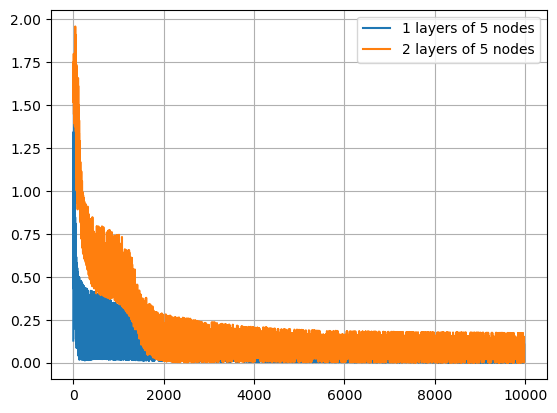

In [199]:
#laatste 3: learning_rate, epochs, batch size
#als batch size = len(inputs), dan betekent dit dus dat alle data getest wordt bij elke update van de weights en de biases

start = time.time()  
activations, weights, biases, cost_a = neural_network_2(inputs, outputs, [5], 1, 10000, len(inputs)) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network_2(inputs, outputs, [5, 5], 1, 10000, len(inputs)) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.grid();
plt.legend();

In [143]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 300, len(inputs)) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 300, len(inputs)) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 300, len(inputs)) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 300, len(inputs)) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

Time taken for 1 layer of 5 nodes: 0.9823470115661621 seconds
Time taken for 2 layes of 5 nodes: 2.1549549102783203 seconds
Time taken for 3 layers of 5 nodes: 7.14258599281311 seconds
Time taken for 4 layers of 5 nodes: 29.755282163619995 seconds


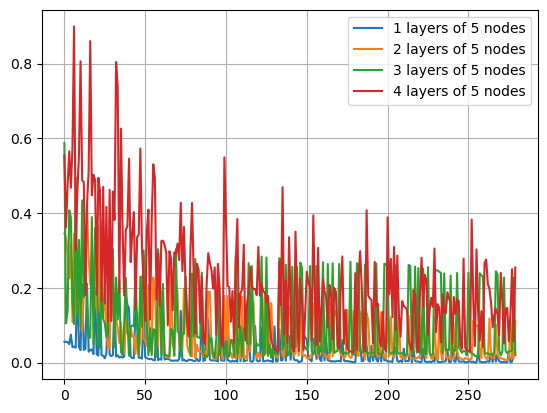

In [144]:
plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

In [145]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [146]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [172]:
def predict(inputs, weights, biases, labels):

    outputs = []

    for i in range(len(inputs)):

        activations = det_activations(inputs[i], weights, biases)
        outputs.append(labels[np.argmax(activations[-1])])

    return outputs

In [173]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [174]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

Time taken: 3719.252261161804 seconds
Accuracy: 0.384


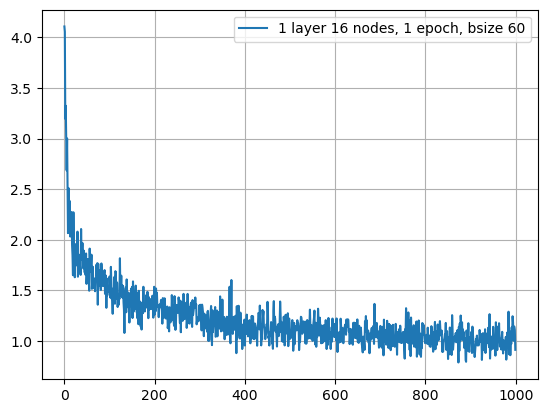

In [177]:
start = time.time()  
activations_0, weights_0, biases_0, cost_0 = neural_network(X_train, y_train, [16], 1, 1, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_0, label="1 layer 16 nodes, 1 epoch, bsize 60");
plt.grid();
plt.legend();

y_predict_0 = predict(X_test, weights_0, biases_0, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_0)))

Time taken: 340.94428873062134 seconds
Accuracy: 0.4242


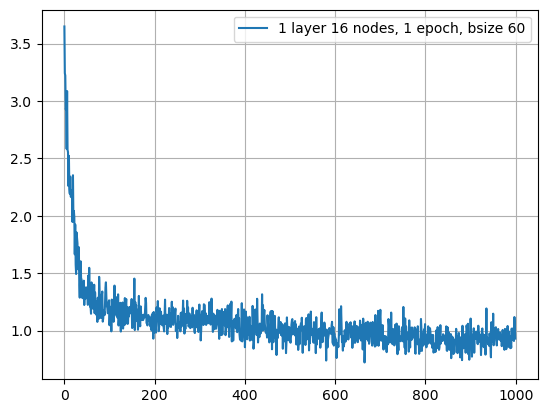

In [175]:
start = time.time()  
activations_1, weights_1, biases_1, cost_1 = neural_network_2(X_train, y_train, [16], 1, 1, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_1, label="1 layer 16 nodes, 1 epoch, bsize 60");
plt.grid();
plt.legend();

y_predict_1 = predict(X_test, weights_1, biases_1, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_1)))

Time taken: 1020.5168719291687 seconds
Accuracy: 0.625


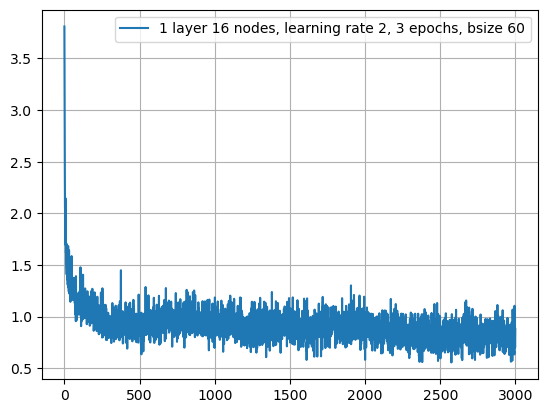

In [176]:
start = time.time()  
activations_2, weights_2, biases_2, cost_2 = neural_network_2(X_train, y_train, [16], 2, 3, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_2, label="1 layer 16 nodes, learning rate 2, 3 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_2 = predict(X_test, weights_2, biases_2, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_2)))

Time taken: 1710.8498730659485 seconds
Accuracy: 0.4292


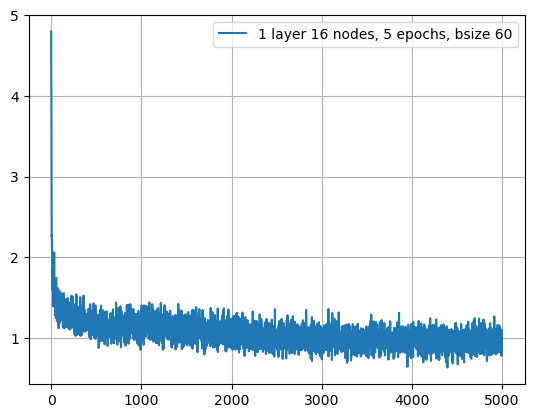

In [178]:
start = time.time()  
activations_3, weights_3, biases_3, cost_3 = neural_network_2(X_train, y_train, [16], 1, 5, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_3, label="1 layer 16 nodes, 5 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_3 = predict(X_test, weights_3, biases_3, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_3)))

/var/folders/tk/6312j0x51lv1_71j8_phv3bc0000gn/T/ipykernel_65632/1919106164.py:2: RuntimeWarning: overflow encountered in exp
  s = 1/(1 + np.exp(-x))


Time taken: 3173.550051212311 seconds
Accuracy: 0.3582


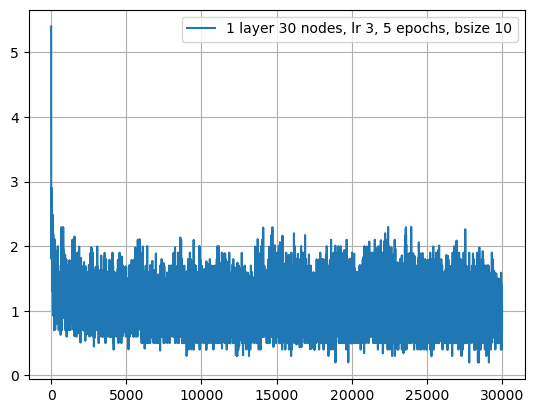

In [179]:
start = time.time()  
activations_4, weights_4, biases_4, cost_4 = neural_network_2(X_train, y_train, [30], 3, 5, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_4, label="1 layer 30 nodes, lr 3, 5 epochs, bsize 10");
plt.grid();
plt.legend();

y_predict_4 = predict(X_test, weights_4, biases_4, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_4)))

Time taken: 3234.0099489688873 seconds
Accuracy: 0.6002


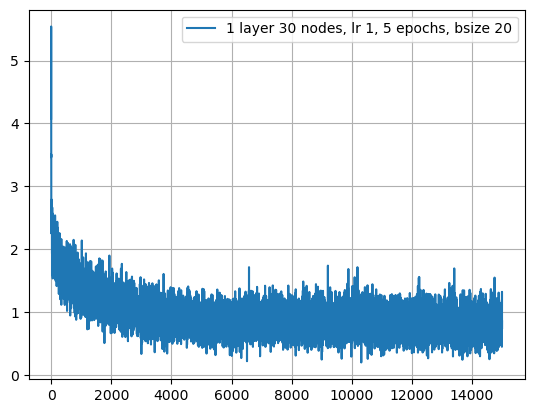

In [180]:
start = time.time()  
activations_5, weights_5, biases_5, cost_5 = neural_network_2(X_train, y_train, [30], 1, 5, 20) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_5, label="1 layer 30 nodes, lr 1, 5 epochs, bsize 20");
plt.grid();
plt.legend();

y_predict_5 = predict(X_test, weights_5, biases_5, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_5)))